In [3]:
pip install geopandas pandas numpy matplotlib seaborn scikit-learn folium mapclassify

Note: you may need to restart the kernel to use updated packages.


In [4]:
import sys
print('Python: {}'.format(sys.version))
# scipy
import scipy
print('scipy: {}'.format(scipy.__version__))
# numpy
import numpy
print('numpy: {}'.format(numpy.__version__))
# matplotlib
import matplotlib
print('matplotlib: {}'.format(matplotlib.__version__))
# pandas
import pandas
print('pandas: {}'.format(pandas.__version__))
# scikit-learn
import sklearn
print('sklearn: {}'.format(sklearn.__version__))
#geopandas  seaborn scikit-learn folium mapclassify
import geopandas
print('geopandas: {}'.format(geopandas.__version__))
#
import seaborn
print('seaborn: {}'.format(seaborn.__version__))
#
import folium
print('folium: {}'.format(folium.__version__))
#
import mapclassify
print('mapclassify: {}'.format(mapclassify.__version__))

Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
scipy: 1.18.0
numpy: 2.5.1
matplotlib: 3.11.1
pandas: 3.0.5
sklearn: 1.9.0
geopandas: 1.1.4
seaborn: 0.13.2
folium: 0.20.0
mapclassify: 2.11.0


In [5]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import folium
from folium.plugins import MarkerCluster

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [6]:
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"

world = gpd.read_file(url)

print("Dataset loaded successfully!")
print("Number of countries:", len(world))

world.head()

Dataset loaded successfully!
Number of countries: 258


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,0,2,Indonesia,IDN,0,2,Sovereign country,1,Indonesia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((117.70361 4.16341, 117.70361 4..."
1,Admin-0 country,0,3,Malaysia,MYS,0,2,Sovereign country,1,Malaysia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((117.70361 4.16341, 117.69711 4..."
2,Admin-0 country,0,2,Chile,CHL,0,2,Sovereign country,1,Chile,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-69.51009 -17.50659, -69.50611..."
3,Admin-0 country,0,3,Bolivia,BOL,0,2,Sovereign country,1,Bolivia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-69.51009 -17.50659, -69.51009 -17.5..."
4,Admin-0 country,0,2,Peru,PER,0,2,Sovereign country,1,Peru,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-69.51009 -17.50659, -69.63832..."


In [7]:
print("Columns:")
print(world.columns.tolist())

print("\nCoordinates Reference System (CRS):")
print(world.crs)

print("\nDataset information:")
print(world.info())

Columns:
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3_VN', 'ADM0_A3

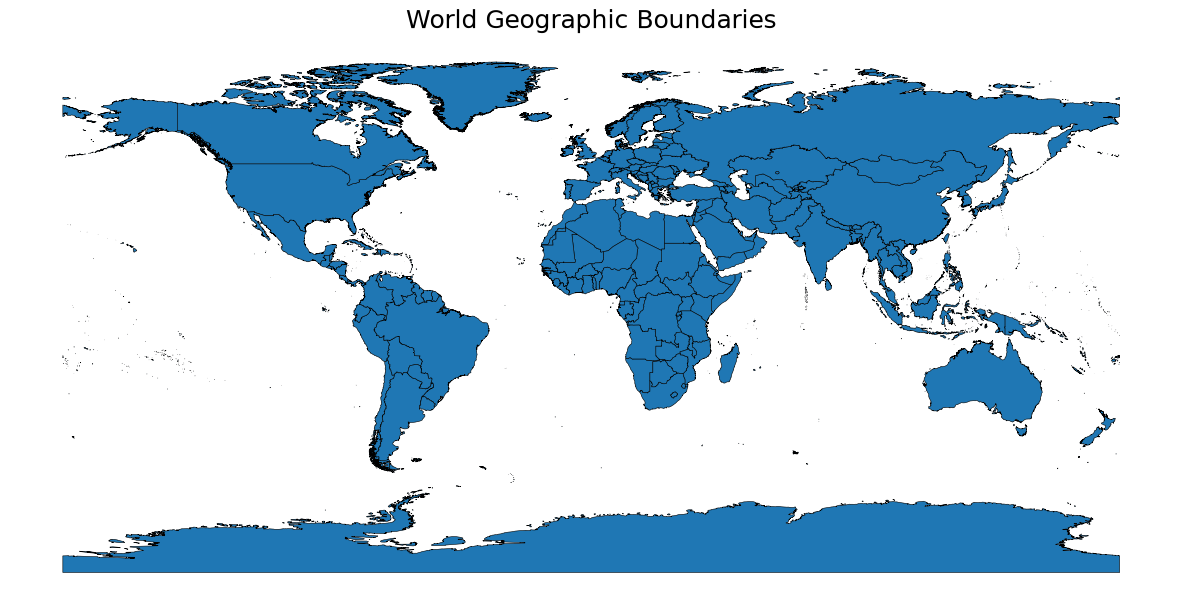

In [13]:
fig, ax = plt.subplots(figsize=(15, 8))

world.plot(
    ax=ax,
    edgecolor="black",
    linewidth=0.4
)

ax.set_title(
    "World Geographic Boundaries",
    fontsize=18
)

ax.set_axis_off()

plt.show()

In [16]:
africa = world[
world['CONTINENT'] == 'Africa'
].copy()

In [17]:
africa

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
13,Admin-0 country,0,2,Ethiopia,ETH,0,2,Sovereign country,1,Ethiopia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((34.0707 9.45459, 34.06689 9.53118, 3..."
14,Admin-0 country,0,3,South Sudan,SDS,0,2,Sovereign country,1,South Sudan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((35.92084 4.61933, 35.85654 4.6196, 3..."
15,Admin-0 country,0,6,Somalia,SOM,0,2,Sovereign country,1,Somalia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((46.46696 6.53829, 46.48805 6.55864, ..."
16,Admin-0 country,0,2,Kenya,KEN,0,2,Sovereign country,1,Kenya,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((35.70585 4.61945, 35.70594 4.6..."
17,Admin-0 country,0,6,Malawi,MWI,0,2,Sovereign country,1,Malawi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((34.96461 -11.57356, 34.65125 -..."
18,Admin-0 country,0,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((32.92086 -9.4079, 32.90546 -9...."
20,Admin-0 country,0,5,Somaliland,SOL,0,2,Sovereign country,1,Somaliland,...,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,"POLYGON ((48.93911 11.24913, 48.93911 11.13674..."
26,Admin-0 country,0,3,Morocco,MAR,0,2,Sovereign country,1,Morocco,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-8.81703 27.66146, -8.81845 27.6594,..."
27,Admin-0 country,0,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,NaN,NaN,Unrecognized,NaN,NaN,NaN,"POLYGON ((-8.81703 27.66146, -8.81654 27.66147..."
30,Admin-0 country,0,4,Republic of the Congo,COG,0,2,Sovereign country,1,Republic of the Congo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((18.62639 3.47687, 18.63455 3.44922, ..."


In [18]:
# Data Cleaning and Preprocessing

print(africa.describe)


<bound method NDFrame.describe of           featurecla  scalerank  LABELRANK                        SOVEREIGNT  \
13   Admin-0 country          0          2                          Ethiopia   
14   Admin-0 country          0          3                       South Sudan   
15   Admin-0 country          0          6                           Somalia   
16   Admin-0 country          0          2                             Kenya   
17   Admin-0 country          0          6                            Malawi   
18   Admin-0 country          0          3       United Republic of Tanzania   
20   Admin-0 country          0          5                        Somaliland   
26   Admin-0 country          0          3                           Morocco   
27   Admin-0 country          0          7                    Western Sahara   
30   Admin-0 country          0          4             Republic of the Congo   
31   Admin-0 country          0          2  Democratic Republic of the Congo   
35   A

In [20]:
print(africa.isnull().sum())

featurecla     0
scalerank      0
LABELRANK      0
SOVEREIGNT     0
SOV_A3         0
              ..
FCLASS_NL     53
FCLASS_SE     54
FCLASS_BD     54
FCLASS_UA     54
geometry       0
Length: 169, dtype: int64


In [21]:
print(f"Duplicates: {africa.duplicated().sum()}")

Duplicates: 0


In [23]:
africa = africa.drop_duplicates(keep='first')

In [24]:
africa

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
13,Admin-0 country,0,2,Ethiopia,ETH,0,2,Sovereign country,1,Ethiopia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((34.0707 9.45459, 34.06689 9.53118, 3..."
14,Admin-0 country,0,3,South Sudan,SDS,0,2,Sovereign country,1,South Sudan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((35.92084 4.61933, 35.85654 4.6196, 3..."
15,Admin-0 country,0,6,Somalia,SOM,0,2,Sovereign country,1,Somalia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((46.46696 6.53829, 46.48805 6.55864, ..."
16,Admin-0 country,0,2,Kenya,KEN,0,2,Sovereign country,1,Kenya,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((35.70585 4.61945, 35.70594 4.6..."
17,Admin-0 country,0,6,Malawi,MWI,0,2,Sovereign country,1,Malawi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((34.96461 -11.57356, 34.65125 -..."
18,Admin-0 country,0,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((32.92086 -9.4079, 32.90546 -9...."
20,Admin-0 country,0,5,Somaliland,SOL,0,2,Sovereign country,1,Somaliland,...,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,Unrecognized,"POLYGON ((48.93911 11.24913, 48.93911 11.13674..."
26,Admin-0 country,0,3,Morocco,MAR,0,2,Sovereign country,1,Morocco,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-8.81703 27.66146, -8.81845 27.6594,..."
27,Admin-0 country,0,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,NaN,NaN,Unrecognized,NaN,NaN,NaN,"POLYGON ((-8.81703 27.66146, -8.81654 27.66147..."
30,Admin-0 country,0,4,Republic of the Congo,COG,0,2,Sovereign country,1,Republic of the Congo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((18.62639 3.47687, 18.63455 3.44922, ..."


In [26]:
import geopandas as gpd
import numpy as np

# ==========================================
# 1. Load Data & Apply Your Filter
# ==========================================
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
world = gpd.read_file(url)

# Your exact filtering code
africa = world[
    world['CONTINENT'] == 'Africa'
].copy()

# ==========================================
# 2. Trim and Rename Columns
# ==========================================
columns_to_keep = [
    'ADMIN', 'ISO_A3', 'SUBREGION', 'POP_EST', 'GDP_MD', 'geometry'
]
africa = africa[columns_to_keep]

africa = africa.rename(columns={
    'ADMIN': 'country',
    'ISO_A3': 'iso_code',
    'SUBREGION': 'subregion',
    'POP_EST': 'population',
    'GDP_MD': 'gdp_millions'
})

# ==========================================
# 3. Handle Natural Earth's "-99" Missing Values
# ==========================================
# Text placeholder
africa['iso_code'] = africa['iso_code'].replace('-99', np.nan)

# Numeric placeholders
numeric_cols = ['population', 'gdp_millions']
for col in numeric_cols:
    africa[col] = africa[col].replace(-99.0, np.nan)

# ==========================================
# 4. Fill Missing Values by African Subregion
# ==========================================
africa['population'] = africa.groupby('subregion')['population'].transform(
    lambda x: x.fillna(x.median())
)
africa['gdp_millions'] = africa.groupby('subregion')['gdp_millions'].transform(
    lambda x: x.fillna(x.median())
)

# ==========================================
# 5. Tidy Text and Reset the Index
# ==========================================
# Standardize capitalization and spacing
africa['country'] = africa['country'].str.strip().str.title()
africa['subregion'] = africa['subregion'].str.strip().str.title()

# Reset index (so rows count nicely from 0 to N instead of keeping original 'world' row numbers)
africa = africa.reset_index(drop=True)

# ==========================================
# 6. Validate the Spatial Data (Geometries)
# ==========================================
# Fix any self-intersecting country borders
africa['geometry'] = africa['geometry'].make_valid()

# Print out the results
print("Cleaning Complete!")
print(f"Number of African nations/territories: {len(africa)}")
print("\nMissing values remaining:")
print(africa.isnull().sum())

# Plot it quickly to verify!
# africa.plot(column='subregion', cmap='Set3', figsize=(8, 8))

Cleaning Complete!
Number of African nations/territories: 55

Missing values remaining:
country         0
iso_code        2
subregion       0
population      0
gdp_millions    0
geometry        0
dtype: int64


In [27]:
# Show rows where iso_code is null
missing_iso = africa[africa['iso_code'].isnull()]
print(missing_iso[['country', 'iso_code']])

       country iso_code
6   Somaliland      NaN
50   Bir Tawil      NaN


In [28]:
# Create a dictionary mapping the country name to your chosen 3-letter code
# (Update the names based on what the print statement above outputs)
custom_iso_mapping = {
    'Somaliland': 'SOL',
    # Replace 'OtherCountry' with the actual second name printed from Step 1
    'OtherCountry': 'XYZ' 
}

# Apply the mapping only to rows where the iso_code is currently missing
for country_name, custom_code in custom_iso_mapping.items():
    africa.loc[africa['country'] == country_name, 'iso_code'] = custom_code

# Verify it worked!
print(f"Remaining missing ISO codes: {africa['iso_code'].isnull().sum()}")

Remaining missing ISO codes: 1


In [29]:
# Find the row where iso_code is STILL missing
last_missing = africa[africa['iso_code'].isnull()]

# Print the name of the country
print("The final missing country is:")
print(last_missing[['country', 'iso_code']])

The final missing country is:
      country iso_code
50  Bir Tawil      NaN


In [30]:
# Assign a custom proxy code to Bir Tawil
africa.loc[africa['country'] == 'Bir Tawil', 'iso_code'] = 'BTW'

# Do a final check to confirm everything is clean!
print(f"Remaining missing ISO codes: {africa['iso_code'].isnull().sum()}")

Remaining missing ISO codes: 0


In [31]:
africa

,country,iso_code,subregion,population,gdp_millions,geometry
0,Ethiopia,ETH,Eastern Africa,112078730.0,95912,"POLYGON ((34.0707 9.45459, 34.06689 9.53118, 3..."
1,South Sudan,SSD,Eastern Africa,11062113.0,11998,"POLYGON ((35.92084 4.61933, 35.85654 4.6196, 3..."
2,Somalia,SOM,Eastern Africa,10192317.3,4719,"POLYGON ((46.46696 6.53829, 46.48805 6.55864, ..."
3,Kenya,KEN,Eastern Africa,52573973.0,95503,"MULTIPOLYGON (((35.70585 4.61945, 35.70594 4.6..."
4,Malawi,MWI,Eastern Africa,18628747.0,7666,"MULTIPOLYGON (((34.96461 -11.57356, 34.65125 -..."
5,United Republic Of Tanzania,TZA,Eastern Africa,58005463.0,63177,"MULTIPOLYGON (((32.92086 -9.4079, 32.90546 -9...."
6,Somaliland,SOL,Eastern Africa,5096159.0,17836,"POLYGON ((48.93911 11.24913, 48.93911 11.13674..."
7,Morocco,MAR,Northern Africa,36471769.0,119700,"POLYGON ((-8.81703 27.66146, -8.81845 27.6594,..."
8,Western Sahara,ESH,Northern Africa,603253.0,907,"POLYGON ((-8.81703 27.66146, -8.81654 27.66147..."
9,Republic Of The Congo,COG,Middle Africa,5380508.0,12267,"POLYGON ((18.62639 3.47687, 18.63455 3.44922, ..."


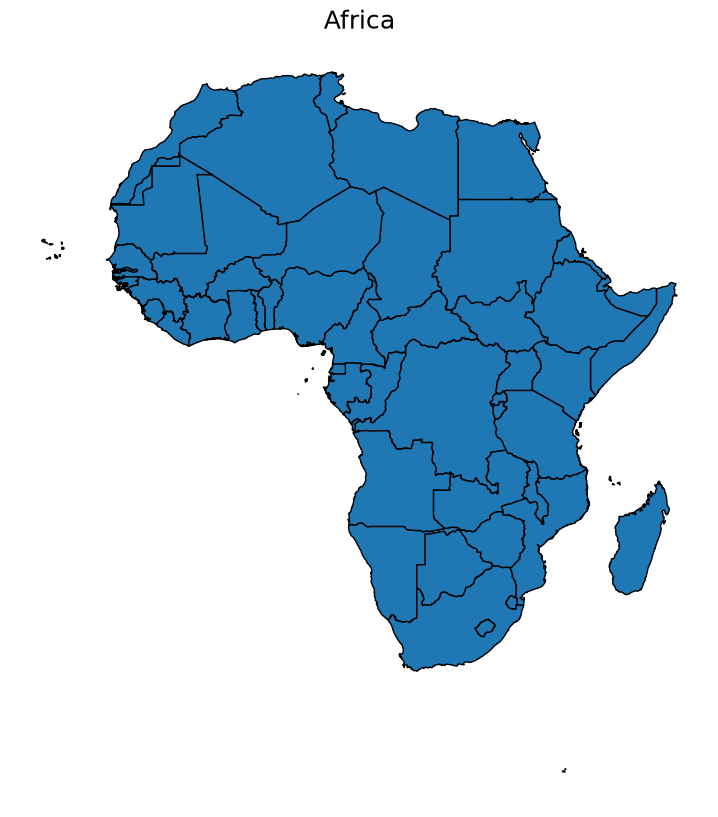

In [33]:
fig, ax = plt.subplots(figsize=(10, 10))

africa.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1
)

ax.set_title(
    "Africa",
    fontsize=18
)

ax.set_axis_off()

plt.show()

In [35]:
# Project Africa to a metric CRS
africa_projected = africa.to_crs(epsg=3395) # EPSG:3395 is a metric projection (World Mercator)

# Unpack all 4 values returned by total_bounds
minx, miny, maxx, maxy = africa_projected.total_bounds

# Set your spacing (1,000,000 meters = 1,000 km)
spacing = 1000000

In [37]:
import numpy as np
import geopandas as gpd

# Project Africa to a metric CRS
africa_projected = africa.to_crs(epsg=3395) # EPSG:3395 is a metric projection (World Mercator)

# FIX 1: Unpack all 4 values returned by total_bounds
minx, miny, maxx, maxy = africa_projected.total_bounds

spacing = 1000000  # 1,000,000 meters = 1,000 km

# FIX 2: Use minx and maxx for the X coordinates (Longitude)
x_cords = np.arange(minx, maxx, spacing)
# Use miny and maxy for the Y coordinates (Latitude)
y_cords = np.arange(miny, maxy, spacing)

points = []
for x in x_cords:
    for y in y_cords:
        points.append((x, y))

# FIX 3: Changed 'gdp' to 'gpd' for GeoDataFrame
grid = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy([p[0] for p in points], [p[1] for p in points]), 
    crs=africa_projected.crs
)  

print("Number of grid points:", len(grid))

Number of grid points: 99


<function matplotlib.pyplot.show(close=None, block=None)>

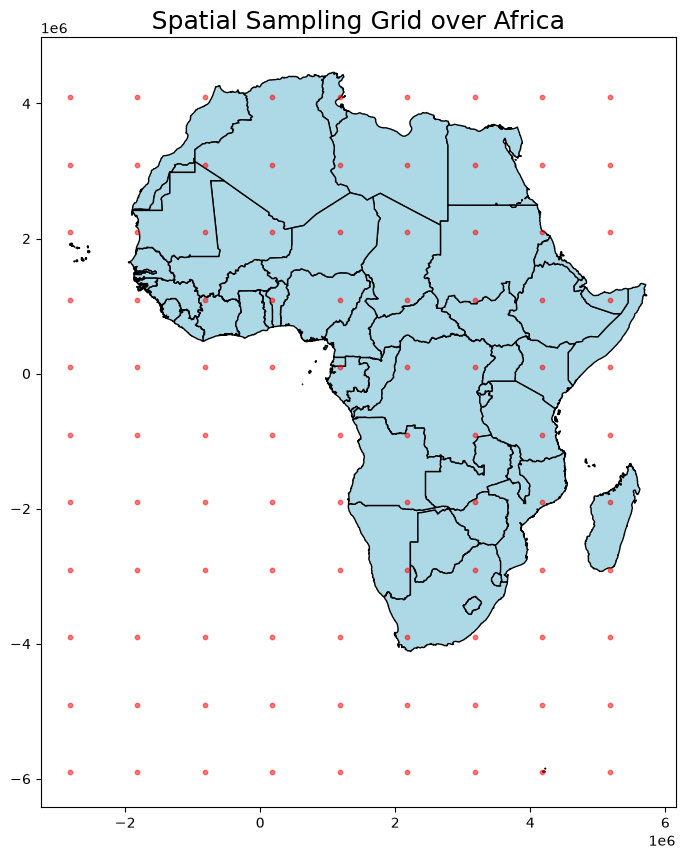

In [39]:
fig, ax = plt.subplots(figsize=(15, 10))
africa_projected.plot(ax=ax, color='lightblue', edgecolor='black')
grid.plot(ax=ax, color='red', markersize=10, alpha=0.5)
ax.set_title("Spatial Sampling Grid over Africa", fontsize=18)
plt.show

In [40]:
import geopandas as gpd

# Important South African locations (Longitude, Latitude)
cities = {
    "Johannesburg": (28.0473, -26.2041),
    "Pretoria": (28.2293, -25.7479),
    "Cape_Town": (18.4241, -33.9249),
    "Durban": (31.0218, -29.8587)
}

# Convert cities to projected coordinates
city_points = {}

for city, (lon, lat) in cities.items():
    # 1. Create the point in standard GPS coordinates (WGS 84 / EPSG:4326)
    point = gpd.GeoSeries(
        gpd.points_from_xy([lon], [lat]),
        crs="EPSG:4326"
    )
    
    # 2. FIX: Project it to match the grid's CRS dynamically (instead of hardcoding 3857)
    point_projected = point.to_crs(grid.crs)

    city_points[city] = point_projected.iloc[0]

# Add X and Y coordinates as independent columns (Great for machine learning later!)
grid["x"] = grid.geometry.x
grid["y"] = grid.geometry.y

# Calculate distances from major cities to every grid point
for city, point in city_points.items():
    # distance() returns meters (since EPSG:3395 uses meters). 
    # Divide by 1000 to convert to kilometers.
    grid[f"distance_{city}_km"] = (
        grid.geometry.distance(point) / 1000
    )

# Check the results
print(grid.head())

                         geometry             x             y  \
0  POINT (-2823109.3 -5905238.88) -2.823109e+06 -5.905239e+06   
1  POINT (-2823109.3 -4905238.88) -2.823109e+06 -4.905239e+06   
2  POINT (-2823109.3 -3905238.88) -2.823109e+06 -3.905239e+06   
3  POINT (-2823109.3 -2905238.88) -2.823109e+06 -2.905239e+06   
4  POINT (-2823109.3 -1905238.88) -2.823109e+06 -1.905239e+06   

   distance_Johannesburg_km  distance_Pretoria_km  distance_Cape_Town_km  \
0               6614.771974           6657.741588            5235.078976   
1               6241.455707           6278.034258            4958.359214   
2               6013.013422           6041.680663            4874.894901   
3               5946.166117           5965.743569            4994.384296   
4               6046.275925           6056.260184            5303.126314   

   distance_Durban_km  
0         6734.442236  
1         6439.758976  
2         6291.921734  
3         6301.274675  
4         6467.135840  


**DEMONSTRATION OF GIS BEFORE TEMPER WITH SPECIFIC DATA SPECIFIFCATIONS(eg. health across afirca, logistics costs, or housing)**

TBC